# Week 1.1: Probability & Neural Networks for Digital Twins

## Learning Objectives
- Understand how AI makes predictions using probability
- Learn the basics of neural networks
- Apply these concepts to building a digital twin

## Digital Twin Context
A **digital twin** is a virtual representation of a physical entity (person, object, system). In this series, we'll build a digital twin that can:
- Predict behaviors and preferences
- Understand and respond to language
- Learn from interactions

## Key Insight
> "AI isn't thinking; it's predicting the next number."

This applies to everything from weather prediction to language generation!

---
## Part 1: Probability Foundations

Let's start with the basics: How does AI make predictions?

In [1]:
# Import required libraries
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
import pandas as pd

# Set random seed for reproducibility
np.random.seed(42)

print("✅ Libraries loaded successfully!")

✅ Libraries loaded successfully!


### 1.1 Simple Prediction: Next Number

Let's simulate a digital twin predicting your next action based on historical data.

Activity Probabilities:
  Sleep: 20.00%
  Work: 40.00%
  Exercise: 13.33%
  Social: 13.33%
  Leisure: 13.33%


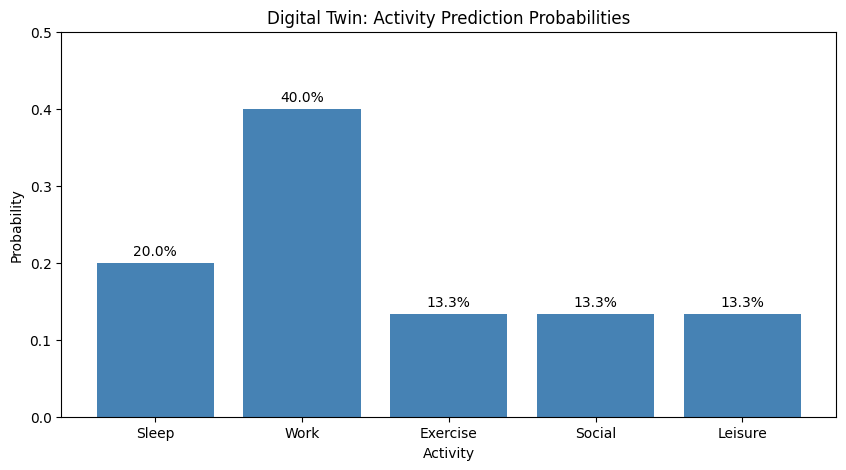

In [2]:
from collections import Counter
import matplotlib.pyplot as plt

# Example: Predicting daily activities (represented as numbers)
# 0=Sleep, 1=Work, 2=Exercise, 3=Social, 4=Leisure

historical_activities = [0, 1, 2, 1, 3, 1, 4, 0, 1, 2, 1, 3, 1, 4, 0]

def calculate_probabilities(sequence):
    """
    Calculate probability distribution from a sequence.

    Args:
        sequence: List of integers representing activities

    Returns:
        dict: Probability of each activity
    """
    counts = Counter(sequence)
    total = len(sequence)
    probabilities = {activity: count/total for activity, count in counts.items()}
    return probabilities

# Calculate probabilities
probs = calculate_probabilities(historical_activities)

# Display results
activity_names = {0: 'Sleep', 1: 'Work', 2: 'Exercise', 3: 'Social', 4: 'Leisure'}
print("Activity Probabilities:")
for activity, prob in sorted(probs.items()):
    print(f"  {activity_names[activity]}: {prob:.2%}")

# Visualize
plt.figure(figsize=(10, 5))
activities = [activity_names[k] for k in sorted(probs.keys())]
probabilities = [probs[k] for k in sorted(probs.keys())]
plt.bar(activities, probabilities, color='steelblue')
plt.title('Digital Twin: Activity Prediction Probabilities')
plt.ylabel('Probability')
plt.xlabel('Activity')
plt.ylim(0, 0.5)
for i, v in enumerate(probabilities):
    plt.text(i, v + 0.01, f'{v:.1%}', ha='center')
plt.show()

### 🎯 Exercise 1.1 (Easy): Understanding Probabilities

**Task**: Modify the historical activities to represent your own daily routine for 2 weeks (14 days).

**Questions**:
1. Which activity has the highest probability?
2. What does this tell you about the pattern in your data?
3. How would adding more data points affect the predictions?

In [3]:
# YOUR CODE HERE
# Create your own sequence of activities (14 values)
my_activities = [0, 2, 1, 3, 0, 2, 1, 4, 2, 3, 1, 2, 3, 0]  # Replace with your pattern

# Calculate and visualize
my_probs = calculate_probabilities(my_activities)

# YOUR ANALYSIS HERE (write answers as comments)
# 1. Highest probability activity:
# 2. Pattern insight:
# 3. Impact of more data:

### 1.2 Conditional Probability: Context Matters

What if predictions depend on previous activities? This is where context comes in!

In [4]:
def calculate_conditional_probabilities(sequence):
    """
    Calculate P(next | current) - probability of next activity given current.

    Args:
        sequence: List of activities

    Returns:
        dict: Nested dictionary of conditional probabilities
    """
    transitions = {}

    for i in range(len(sequence) - 1):
        current = sequence[i]
        next_activity = sequence[i + 1]

        if current not in transitions:
            transitions[current] = []
        transitions[current].append(next_activity)

    # Convert to probabilities
    conditional_probs = {}
    for current, next_list in transitions.items():
        counts = Counter(next_list)
        total = len(next_list)
        conditional_probs[current] = {activity: count/total for activity, count in counts.items()}

    return conditional_probs

# Calculate conditional probabilities
cond_probs = calculate_conditional_probabilities(historical_activities)

# Display
print("Conditional Probabilities: P(Next | Current)\n")
for current, next_probs in cond_probs.items():
    print(f"After {activity_names[current]}:")
    for next_activity, prob in sorted(next_probs.items()):
        print(f"  → {activity_names[next_activity]}: {prob:.2%}")
    print()

Conditional Probabilities: P(Next | Current)

After Sleep:
  → Work: 100.00%

After Work:
  → Exercise: 33.33%
  → Social: 33.33%
  → Leisure: 33.33%

After Exercise:
  → Work: 100.00%

After Social:
  → Work: 100.00%

After Leisure:
  → Sleep: 100.00%



### 🎯 Exercise 1.2 (Intermediate): Markov Chain Prediction

**Task**: Build a simple predictor that uses conditional probabilities to predict the next activity.

**Challenge**: What happens after "Work"? Which activity is most likely?

In [7]:
def predict_next_activity(current_activity, conditional_probs):
    """
    Predict the most likely next activity.

    Args:
        current_activity: Current activity code
        conditional_probs: Dictionary of conditional probabilities

    Returns:
        int: Most likely next activity
    """
    # YOUR CODE HERE
    # Hint: Find the activity with maximum probability given current_activity
    if current_activity not in conditional_probs:
        return None

    next_probs = conditional_probs[current_activity]
    print(next_probs.get)
    predicted_activity = max(next_probs, key=next_probs.get)

    return predicted_activity

# Test your function
current = 1  # Work
predicted = predict_next_activity(current, cond_probs)
print(f"After {activity_names[current]}, most likely next: {activity_names.get(predicted, 'Unknown')}")

# BONUS: Predict a sequence of 5 activities starting from "Work"

# Predict a sequence of 5 activities starting from Work
current = 1  # Work
sequence = [current]

for _ in range(5):
    predicted = predict_next_activity(current, cond_probs)

    if predicted is None:
        break

    sequence.append(predicted)
    current = predicted

# Display the sequence
print("Predicted activity sequence:")

for activity in sequence:
    print(activity_names.get(activity, "Unknown"))


<built-in method get of dict object at 0x78a8fa015440>
After Work, most likely next: Exercise
<built-in method get of dict object at 0x78a8fa015440>
<built-in method get of dict object at 0x78a8fa015340>
<built-in method get of dict object at 0x78a8fa015440>
<built-in method get of dict object at 0x78a8fa015340>
<built-in method get of dict object at 0x78a8fa015440>
Predicted activity sequence:
Work
Exercise
Work
Exercise
Work
Exercise


---
## Part 2: Neural Networks Basics

Now let's see how neural networks learn to make predictions!

### 2.1 The Perceptron: Building Block of Neural Networks

A perceptron is the simplest neural network - it takes inputs, applies weights, and produces an output.

In [8]:
import numpy as np

def sigmoid(x):
    """Sigmoid activation function."""
    return 1 / (1 + np.exp(-x))

def perceptron(inputs, weights, bias):
    """
    Simple perceptron implementation.

    Args:
        inputs: Array of input values
        weights: Array of weights
        bias: Bias term

    Returns:
        float: Output after activation
    """
    # Calculate weighted sum
    weighted_sum = np.dot(inputs, weights) + bias
    # Apply activation function
    output = sigmoid(weighted_sum)
    return output

# Example: Predicting if someone will exercise based on features
# Features: [hours_of_sleep, free_time_hours, energy_level (0-1)]
person_features = np.array([7, 2, 0.8])  # 7 hours sleep, 2 hours free time, high energy

# Initialize random weights
weights = np.array([0.3, 0.5, 0.7])
bias = -0.5

prediction = perceptron(person_features, weights, bias)
print(f"Probability of exercising: {prediction:.2%}")
print(f"Prediction: {'Will exercise' if prediction > 0.5 else 'Will not exercise'}")

Probability of exercising: 95.93%
Prediction: Will exercise


### 🎯 Exercise 2.1 (Easy): Feature Engineering

**Task**: Modify the features and observe how the prediction changes.

**Questions**:
1. What happens when sleep hours decrease to 4?
2. What if free time increases to 4 hours?
3. Which feature seems to have the most impact based on the weights?

In [11]:
# YOUR CODE HERE
# Test different feature combinations

test_cases = [
    np.array([5, 2, 0.8]),  # Low sleep
    np.array([7, 3, 0.8]),  # More free time
    np.array([7, 2, 0.3]),  # Low energy
]


# Test each case and analyze results

test_labels = [
    "Low sleep",
    "More free time",
    "Low energy"
]

for label, features in zip(test_labels, test_cases):
    prediction = perceptron(features, weights, bias)

    result = "Will exercise" if prediction > 0.5 else "Will not exercise"

    print(f"\nTest case: {label}")
    print(f"Features: {features}")
    print(f"Probability of exercising: {prediction:.2%}")
    print(f"Prediction: {result}")



Test case: Low sleep
Features: [5.  2.  0.8]
Probability of exercising: 92.82%
Prediction: Will exercise

Test case: More free time
Features: [7.  3.  0.8]
Probability of exercising: 97.49%
Prediction: Will exercise

Test case: Low energy
Features: [7.  2.  0.3]
Probability of exercising: 94.32%
Prediction: Will exercise


### 2.2 Training a Simple Neural Network





Let's see how a network learns by adjusting weights!

In [12]:
class SimpleNeuralNetwork:
    """A simple neural network with one hidden layer."""

    def __init__(self, input_size, hidden_size, output_size):
        # Initialize weights randomly
        self.W1 = np.random.randn(input_size, hidden_size) * 0.5
        self.b1 = np.zeros((1, hidden_size))
        self.W2 = np.random.randn(hidden_size, output_size) * 0.5
        self.b2 = np.zeros((1, output_size))

        # Store training history
        self.loss_history = []

    def forward(self, X):
        """Forward pass through the network."""
        self.z1 = np.dot(X, self.W1) + self.b1
        self.a1 = sigmoid(self.z1)
        self.z2 = np.dot(self.a1, self.W2) + self.b2
        self.a2 = sigmoid(self.z2)
        return self.a2

    def backward(self, X, y, output, learning_rate=0.1):
        """Backward pass - update weights."""
        m = X.shape[0]

        # Calculate gradients
        dz2 = output - y
        dW2 = np.dot(self.a1.T, dz2) / m
        db2 = np.sum(dz2, axis=0, keepdims=True) / m

        da1 = np.dot(dz2, self.W2.T)
        dz1 = da1 * self.a1 * (1 - self.a1)
        dW1 = np.dot(X.T, dz1) / m
        db1 = np.sum(dz1, axis=0, keepdims=True) / m

        # Update weights
        self.W2 -= learning_rate * dW2
        self.b2 -= learning_rate * db2
        self.W1 -= learning_rate * dW1
        self.b1 -= learning_rate * db1

    def train(self, X, y, epochs=1000, learning_rate=0.1):
        """Train the network."""
        for epoch in range(epochs):
            # Forward pass
            output = self.forward(X)

            # Calculate loss
            loss = np.mean((output - y) ** 2)
            self.loss_history.append(loss)

            # Backward pass
            self.backward(X, y, output, learning_rate)

            if epoch % 100 == 0:
                print(f"Epoch {epoch}, Loss: {loss:.4f}")

    def predict(self, X):
        """Make predictions."""
        return self.forward(X)

# Create training data for digital twin
# Features: [day_of_week (0-6), time_of_day (0-23), weather (0-1), mood (0-1)]
# Target: [probability of social activity]

np.random.seed(42)
X_train = np.random.rand(100, 4)
# Simulate pattern: social activity more likely on weekends (day > 5) and good weather
y_train = ((X_train[:, 0] > 0.7) & (X_train[:, 2] > 0.5)).astype(float).reshape(-1, 1)
y_train += np.random.rand(100, 1) * 0.2  # Add noise
y_train = np.clip(y_train, 0, 1)

# Create and train network
nn = SimpleNeuralNetwork(input_size=4, hidden_size=8, output_size=1)
print("Training neural network...\n")
nn.train(X_train, y_train, epochs=500, learning_rate=0.5)

Training neural network...

Epoch 0, Loss: 0.5069
Epoch 100, Loss: 0.1061
Epoch 200, Loss: 0.0863
Epoch 300, Loss: 0.0678
Epoch 400, Loss: 0.0550


In [ ]:
# Visualize training progress
plt.figure(figsize=(10, 5))
plt.plot(nn.loss_history)
plt.title('Neural Network Training: Loss Over Time')
plt.xlabel('Epoch')
plt.ylabel('Mean Squared Error')
plt.grid(True, alpha=0.3)
plt.show()

print(f"\nFinal loss: {nn.loss_history[-1]:.4f}")

### 🎯 Exercise 2.2 (Intermediate): Digital Twin Prediction

**Task**: Test the trained network on new scenarios and interpret results.

**Scenarios to test**:
1. Weekend evening (day=6, time=18, weather=0.8, mood=0.9)
2. Weekday morning (day=2, time=8, weather=0.3, mood=0.5)
3. Weekend with bad weather (day=5, time=14, weather=0.2, mood=0.6)

In [14]:
# YOUR CODE HERE
# Normalize inputs (scale to 0-1 range)
def normalize_input(day, time, weather, mood):
    return np.array([[day/7, time/24, weather, mood]])

# Test scenarios
scenarios = [
    ("Weekend evening, good weather", 6, 18, 0.8, 0.9),
    ("Weekday morning, poor weather", 2, 8, 0.3, 0.5),
    ("Weekend afternoon, bad weather", 5, 14, 0.2, 0.6),
]



# Make predictions and analyze

for name, day, time, weather, mood in scenarios:
    X_test = normalize_input(day, time, weather, mood)
    prediction = nn.predict(X_test)

    probability = prediction[0][0]
    result = "Likely social activity" if probability >= 0.5 else "Unlikely social activity"

    print(f"Scenario: {name}")
    print(f"  Day: {day}, Time: {time}:00")
    print(f"  Weather: {weather:.1f}, Mood: {mood:.1f}")
    print(f"  Social activity probability: {probability:.2%}")
    print(f"  Prediction: {result}\n")

# Display training summary
print(f"Training completed.")
print(f"Initial loss: {nn.loss_history[0]:.4f}")
print(f"Final loss:   {nn.loss_history[-1]:.4f}")


Scenario: Weekend evening, good weather
  Day: 6, Time: 18:00
  Weather: 0.8, Mood: 0.9
  Social activity probability: 72.61%
  Prediction: Likely social activity

Scenario: Weekday morning, poor weather
  Day: 2, Time: 8:00
  Weather: 0.3, Mood: 0.5
  Social activity probability: 6.27%
  Prediction: Unlikely social activity

Scenario: Weekend afternoon, bad weather
  Day: 5, Time: 14:00
  Weather: 0.2, Mood: 0.6
  Social activity probability: 22.70%
  Prediction: Unlikely social activity

Training completed.
Initial loss: 0.5069
Final loss:   0.0474


### 🎯 Exercise 2.3 (Advanced): Improve the Digital Twin

**Task**: Enhance the neural network to make better predictions.

**Challenges**:
1. Add more training data with realistic patterns
2. Experiment with different network architectures (hidden layer size)
3. Try different learning rates
4. Add a second hidden layer
5. Create a visualization showing prediction accuracy

Training samples: 1600
Testing samples: 400
Epoch 0, Loss: 0.2937
Epoch 100, Loss: 0.2520
Epoch 200, Loss: 0.2513
Epoch 300, Loss: 0.2508
Epoch 400, Loss: 0.2504
Epoch 500, Loss: 0.2500
Epoch 600, Loss: 0.2495
Epoch 700, Loss: 0.2491
Epoch 800, Loss: 0.2487
Epoch 900, Loss: 0.2482
Hidden units:  4 | Learning rate: 0.1 | Accuracy: 61.00% | MSE: 0.2478
Epoch 0, Loss: 0.2937
Epoch 100, Loss: 0.2499
Epoch 200, Loss: 0.2476
Epoch 300, Loss: 0.2439
Epoch 400, Loss: 0.2384
Epoch 500, Loss: 0.2312
Epoch 600, Loss: 0.2244
Epoch 700, Loss: 0.2197
Epoch 800, Loss: 0.2173
Epoch 900, Loss: 0.2162
Hidden units:  4 | Learning rate: 0.5 | Accuracy: 63.25% | MSE: 0.2233
Epoch 0, Loss: 0.2937
Epoch 100, Loss: 0.2487
Epoch 200, Loss: 0.2430
Epoch 300, Loss: 0.2327
Epoch 400, Loss: 0.2223
Epoch 500, Loss: 0.2173
Epoch 600, Loss: 0.2159
Epoch 700, Loss: 0.2156
Epoch 800, Loss: 0.2155
Epoch 900, Loss: 0.2154
Hidden units:  4 | Learning rate: 0.8 | Accuracy: 62.25% | MSE: 0.2240
Epoch 0, Loss: 0.3008
Epoch 1

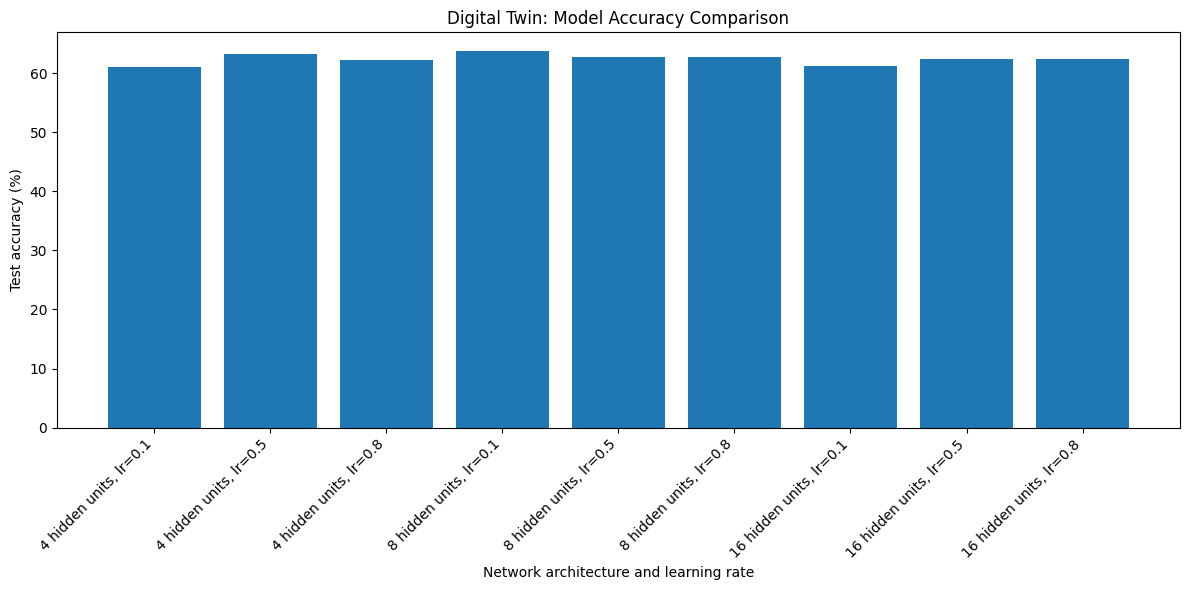

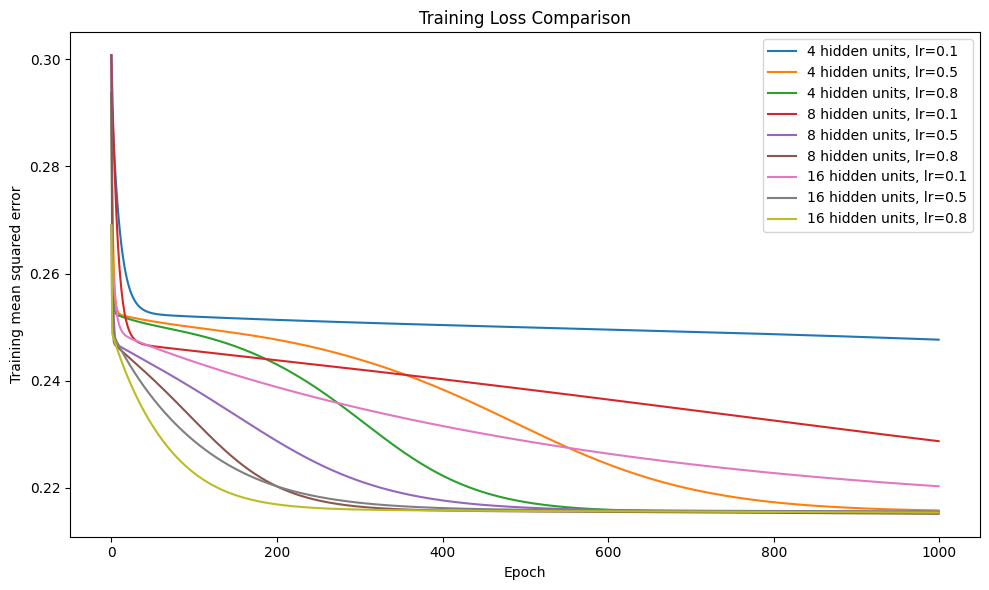


Best configuration:
Architecture: 8 hidden units
Learning rate: 0.1
Test accuracy: 63.75%
Test MSE: 0.2321


In [15]:

import numpy as np
import matplotlib.pyplot as plt

# Challenge 1: Generate more realistic training data
def generate_realistic_data(n_samples=500, seed=42):
    """
    Generate synthetic data for predicting social activity.

    Features, all normalized to [0, 1]:
        day: day of week (0=Monday, 1=Sunday)
        time: time of day (0=midnight, 1=23:00)
        weather: 0=poor, 1=good
        mood: 0=low, 1=high

    Target:
        0 = no social activity
        1 = social activity
    """
    rng = np.random.default_rng(seed)

    day = rng.integers(0, 7, n_samples) / 6.0
    time = rng.integers(0, 24, n_samples) / 23.0
    weather = rng.random(n_samples)
    mood = rng.random(n_samples)

    X = np.column_stack([day, time, weather, mood])

    # Weekend, evening, good weather, and good mood
    # increase the probability of social activity.
    weekend = (day >= 5 / 6).astype(float)
    evening = np.exp(-0.5 * ((time - 0.78) / 0.18) ** 2)

    score = (
        -2.0
        + 1.5 * weekend
        + 1.4 * evening
        + 1.2 * weather
        + 1.0 * mood
    )

    probabilities = sigmoid(score)
    y = (rng.random(n_samples) < probabilities).astype(float)
    y = y.reshape(-1, 1)

    return X, y


# Generate data and split into training and testing sets
X, y = generate_realistic_data(n_samples=2000)

rng = np.random.default_rng(42)
indices = rng.permutation(len(X))
split = int(0.8 * len(X))

train_idx = indices[:split]
test_idx = indices[split:]

X_train, y_train = X[train_idx], y[train_idx]
X_test, y_test = X[test_idx], y[test_idx]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


# Challenge 2: Compare different architectures and learning rates
architectures = [
    (4, 4, 1),    # Small hidden layer
    (4, 8, 1),    # Medium hidden layer
    (4, 16, 1),   # Large hidden layer
]

learning_rates = [0.1, 0.5, 0.8]

results = []

for input_size, hidden_size, output_size in architectures:
    for lr in learning_rates:
        np.random.seed(42)

        model = SimpleNeuralNetwork(
            input_size=input_size,
            hidden_size=hidden_size,
            output_size=output_size
        )

        model.train(
            X_train, y_train,
            epochs=1000,
            learning_rate=lr
        )

        predictions = model.predict(X_test)

        # Binary classification accuracy
        predicted_classes = (predictions >= 0.5).astype(int)
        accuracy = np.mean(predicted_classes == y_test)

        # Mean squared error
        mse = np.mean((predictions - y_test) ** 2)

        results.append({
            "architecture": f"{hidden_size} hidden units",
            "learning_rate": lr,
            "accuracy": accuracy,
            "mse": mse,
            "loss_history": model.loss_history
        })

        print(
            f"Hidden units: {hidden_size:2d} | "
            f"Learning rate: {lr:.1f} | "
            f"Accuracy: {accuracy:.2%} | "
            f"MSE: {mse:.4f}"
        )


# Challenge 3: Visualize prediction accuracy
labels = [
    f"{r['architecture']}, lr={r['learning_rate']}"
    for r in results
]
accuracies = [r["accuracy"] * 100 for r in results]

plt.figure(figsize=(12, 6))
plt.bar(range(len(labels)), accuracies)
plt.xticks(range(len(labels)), labels, rotation=45, ha="right")
plt.ylabel("Test accuracy (%)")
plt.xlabel("Network architecture and learning rate")
plt.title("Digital Twin: Model Accuracy Comparison")
plt.tight_layout()
plt.show()


# Visualize the loss curves
plt.figure(figsize=(10, 6))

for r in results:
    plt.plot(
        r["loss_history"],
        label=f"{r['architecture']}, lr={r['learning_rate']}"
    )

plt.xlabel("Epoch")
plt.ylabel("Training mean squared error")
plt.title("Training Loss Comparison")
plt.legend()
plt.tight_layout()
plt.show()


# Identify the best configuration based on test accuracy
best = max(results, key=lambda r: r["accuracy"])

print("\nBest configuration:")
print("Architecture:", best["architecture"])
print("Learning rate:", best["learning_rate"])
print(f"Test accuracy: {best['accuracy']:.2%}")
print(f"Test MSE: {best['mse']:.4f}")


Epoch 0, Loss: 0.3022
Epoch 100, Loss: 0.2472
Epoch 200, Loss: 0.2436
Epoch 300, Loss: 0.2369
Epoch 400, Loss: 0.2272
Epoch 500, Loss: 0.2198
Epoch 600, Loss: 0.2169
Epoch 700, Loss: 0.2160
Epoch 800, Loss: 0.2158
Epoch 900, Loss: 0.2157

Two-hidden-layer test accuracy: 63.50%
Two-hidden-layer test MSE: 0.2239


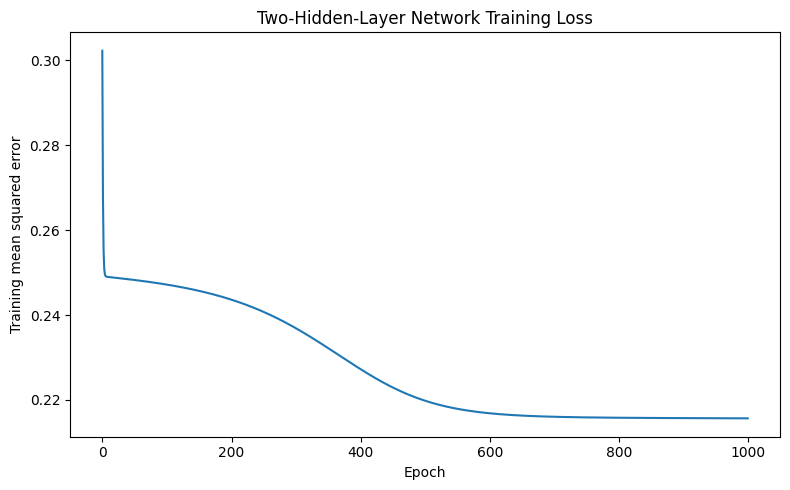

In [16]:

class DeepNeuralNetwork:
    """Neural network with two hidden layers."""

    def __init__(self, input_size, hidden1_size, hidden2_size, output_size):
        self.W1 = np.random.randn(input_size, hidden1_size) * 0.5
        self.b1 = np.zeros((1, hidden1_size))

        self.W2 = np.random.randn(hidden1_size, hidden2_size) * 0.5
        self.b2 = np.zeros((1, hidden2_size))

        self.W3 = np.random.randn(hidden2_size, output_size) * 0.5
        self.b3 = np.zeros((1, output_size))

        self.loss_history = []

    def forward(self, X):
        self.z1 = X @ self.W1 + self.b1
        self.a1 = sigmoid(self.z1)

        self.z2 = self.a1 @ self.W2 + self.b2
        self.a2 = sigmoid(self.z2)

        self.z3 = self.a2 @ self.W3 + self.b3
        self.a3 = sigmoid(self.z3)

        return self.a3

    def backward(self, X, y, output, learning_rate=0.1):
        m = X.shape[0]

        dz3 = output - y
        dW3 = self.a2.T @ dz3 / m
        db3 = np.sum(dz3, axis=0, keepdims=True) / m

        da2 = dz3 @ self.W3.T
        dz2 = da2 * self.a2 * (1 - self.a2)
        dW2 = self.a1.T @ dz2 / m
        db2 = np.sum(dz2, axis=0, keepdims=True) / m

        da1 = dz2 @ self.W2.T
        dz1 = da1 * self.a1 * (1 - self.a1)
        dW1 = X.T @ dz1 / m
        db1 = np.sum(dz1, axis=0, keepdims=True) / m

        self.W3 -= learning_rate * dW3
        self.b3 -= learning_rate * db3

        self.W2 -= learning_rate * dW2
        self.b2 -= learning_rate * db2

        self.W1 -= learning_rate * dW1
        self.b1 -= learning_rate * db1

    def train(self, X, y, epochs=1000, learning_rate=0.1):
        for epoch in range(epochs):
            output = self.forward(X)
            loss = np.mean((output - y) ** 2)
            self.loss_history.append(loss)

            self.backward(X, y, output, learning_rate)

            if epoch % 100 == 0:
                print(f"Epoch {epoch}, Loss: {loss:.4f}")

    def predict(self, X):
        return self.forward(X)


# Train and evaluate the network with two hidden layers
np.random.seed(42)

deep_nn = DeepNeuralNetwork(
    input_size=4,
    hidden1_size=16,
    hidden2_size=8,
    output_size=1
)

deep_nn.train(
    X_train, y_train,
    epochs=1000,
    learning_rate=0.5
)

deep_predictions = deep_nn.predict(X_test)
deep_classes = (deep_predictions >= 0.5).astype(int)

deep_accuracy = np.mean(deep_classes == y_test)
deep_mse = np.mean((deep_predictions - y_test) ** 2)

print(f"\nTwo-hidden-layer test accuracy: {deep_accuracy:.2%}")
print(f"Two-hidden-layer test MSE: {deep_mse:.4f}")

plt.figure(figsize=(8, 5))
plt.plot(deep_nn.loss_history)
plt.xlabel("Epoch")
plt.ylabel("Training mean squared error")
plt.title("Two-Hidden-Layer Network Training Loss")
plt.tight_layout()
plt.show()


---
## Part 3: Connecting to LLMs

How does this relate to Large Language Models?

### 3.1 From Activities to Words

LLMs work exactly like our activity predictor, but with words!

Given text: I love coding in Python because it is

Predicted next word probabilities:
  fun: 19.58%
  elegant: 18.07%
  easy: 16.53%
  versatile: 15.68%
  powerful: 15.56%
  simple: 8.02%
  clear: 6.55%


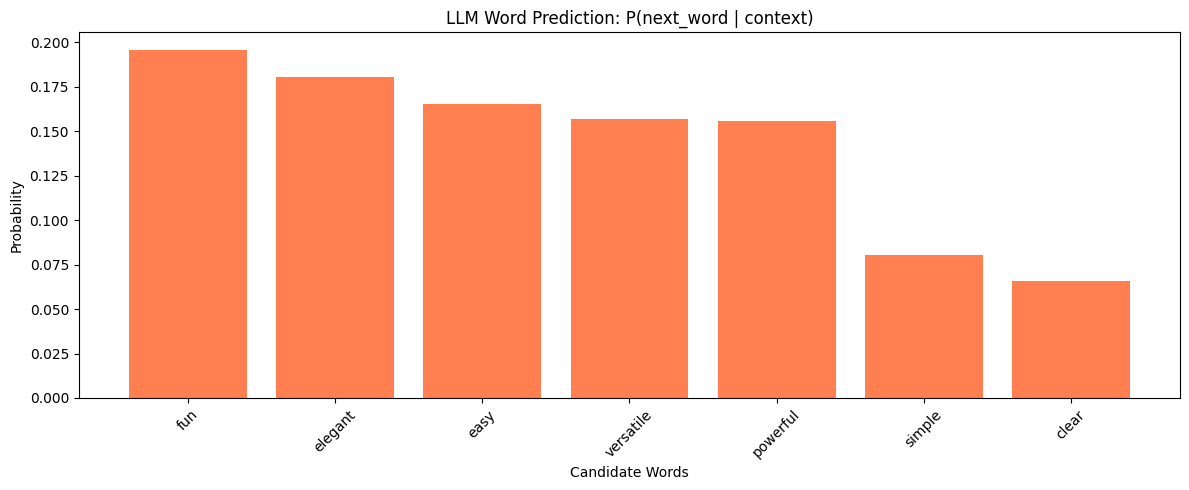

In [17]:
# Simple word prediction example
text_sequence = "I love coding in Python because it is"
words = text_sequence.split()

# Simulate word prediction
word_vocab = ['fun', 'easy', 'powerful', 'versatile', 'simple', 'clear', 'elegant']
word_probs = np.random.rand(len(word_vocab))
word_probs = word_probs / word_probs.sum()  # Normalize to probabilities

# Create probability distribution
word_dist = dict(zip(word_vocab, word_probs))
word_dist = dict(sorted(word_dist.items(), key=lambda x: x[1], reverse=True))

print("Given text:", text_sequence)
print("\nPredicted next word probabilities:")
for word, prob in word_dist.items():
    print(f"  {word}: {prob:.2%}")

# Visualize
plt.figure(figsize=(12, 5))
plt.bar(word_dist.keys(), word_dist.values(), color='coral')
plt.title('LLM Word Prediction: P(next_word | context)')
plt.ylabel('Probability')
plt.xlabel('Candidate Words')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 🎯 Exercise 3.1 (Conceptual): Understanding LLMs

**Questions**:
1. How is predicting the next word similar to predicting the next activity?
2. What role does probability play in both cases?
3. Why might an LLM sometimes generate unexpected words?
4. How does context (previous words) help make better predictions?

Write your answers in the cell below:

**Your Answers:**

1. Similarity between word and activity prediction: Both tasks use the information available so far to estimate what is most likely to happen next.
   -

2. Role of probability: The role of probaility is to measures how likely each possible outcome is.
   -

3. Unexpected generations: Probability: A word that is not the most likely can still have a nonzero probability and may be selected.
Random sampling: Language models can sample from several possible next tokens instead of always selecting the highest-probability token.
Context ambiguity: A sentence can have multiple reasonable continuations.
Limited knowledge: The model may not have learned the relevant pattern or may misunderstand the context.
   -

4. Importance of context:Context helps a model narrow down the possible next words or activities by considering what came before.
   -

---
## Summary & Key Takeaways

### What We Learned:
1. **Probability**: AI predicts by calculating probabilities based on historical patterns
2. **Conditional Probability**: Context matters - knowing what came before improves predictions
3. **Neural Networks**: Learn patterns by adjusting weights through training
4. **Digital Twin**: Can model behaviors using probabilistic predictions
5. **LLM Connection**: Language models are sophisticated versions of these basic concepts

### Next Steps:
In the next notebook, we'll explore:
- How LLMs represent words (embeddings)
- Transformer architecture
- Attention mechanisms
- Building a simple language model for your digital twin

---
## 🏆 Challenge Project (Advanced)

**Build Your Own Digital Twin Predictor**

Create a system that:
1. Collects data about your daily patterns (sleep, activities, mood, etc.)
2. Trains a neural network to predict your next likely activity
3. Evaluates prediction accuracy
4. Visualizes patterns it learned

**Bonus**: Add temporal features (day of week, time of day) and see how they improve predictions!

            timestamp activity  sleep_hours  mood  energy
0 2026-10-12 07:00:00    Sleep            7     4       3
1 2026-10-12 08:00:00      Eat            7     4       4
2 2026-10-12 09:00:00     Work            7     4       4
3 2026-10-12 12:00:00      Eat            7     3       3
4 2026-10-12 13:00:00     Work            7     3       3

Total activity records: 46
Number of usable records: 44

Activity frequencies:
activity
Eat         13
Work         9
Sleep        8
Travel       4
Study        4
Relax        4
Exercise     2
Name: count, dtype: int64

--- Model comparison ---
Most-common-activity baseline: 33.33%
Neural network without time:    55.56%
Neural network with time:       55.56%

--- Temporal model report ---
              precision    recall  f1-score   support

         Eat       0.50      0.67      0.57         3
    Exercise       0.00      0.00      0.00         0
       Relax       0.00      0.00      0.00         1
       Sleep       1.00      0.50      0.6

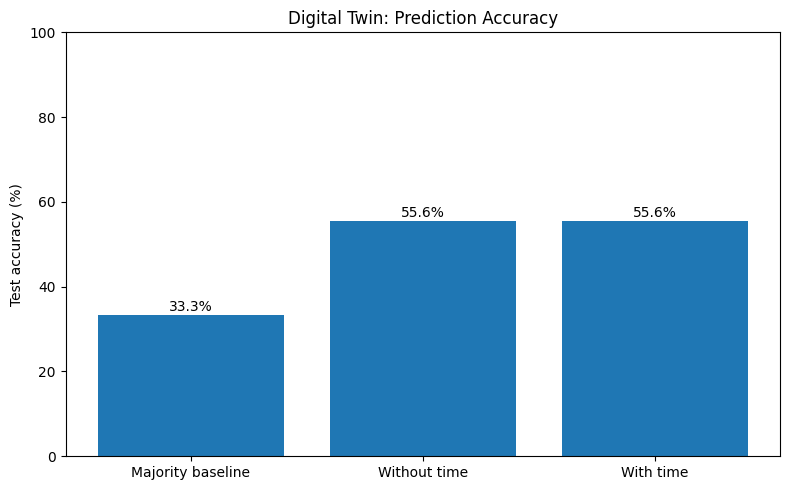

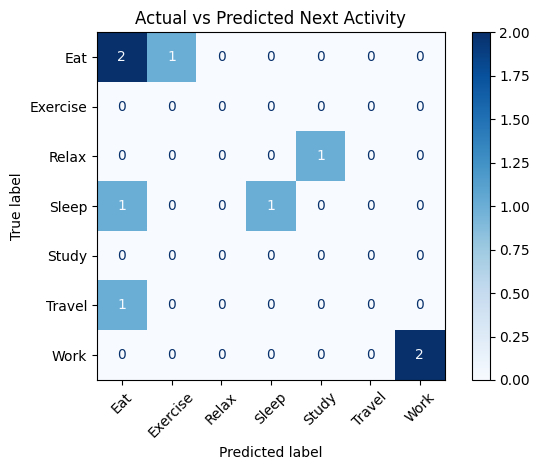


--- Next activity prediction ---
Current activity: Relax
Recorded at: 2026-10-16 20:00:00
Eat: 80.55%
Sleep: 12.70%
Study: 6.69%


In [19]:
# YOUR CHALLENGE PROJECT CODE HERE
# This is your space to be creative!

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neural_network import MLPClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)


# --------------------------------------------------
# 1. Load and prepare daily activity data
# --------------------------------------------------


import pandas as pd
import numpy as np

# Daily activity data stored directly in an array
daily_activities = [
    ["2026-10-12 07:00", "Sleep", 7, 4, 3],
    ["2026-10-12 08:00", "Eat", 7, 4, 4],
    ["2026-10-12 09:00", "Work", 7, 4, 4],
    ["2026-10-12 12:00", "Eat", 7, 3, 3],
    ["2026-10-12 13:00", "Work", 7, 3, 3],
    ["2026-10-12 17:00", "Travel", 7, 4, 3],
    ["2026-10-12 18:00", "Exercise", 7, 4, 4],
    ["2026-10-12 19:00", "Eat", 7, 4, 4],
    ["2026-10-12 20:00", "Study", 7, 4, 3],
    ["2026-10-12 22:00", "Sleep", 7, 4, 2],

    ["2026-10-13 07:00", "Sleep", 6, 3, 2],
    ["2026-10-13 08:00", "Eat", 6, 3, 3],
    ["2026-10-13 09:00", "Work", 6, 3, 3],
    ["2026-10-13 12:00", "Eat", 6, 3, 2],
    ["2026-10-13 13:00", "Work", 6, 3, 3],
    ["2026-10-13 17:00", "Travel", 6, 4, 3],
    ["2026-10-13 18:00", "Relax", 6, 4, 3],
    ["2026-10-13 20:00", "Study", 6, 4, 3],
    ["2026-10-13 22:00", "Sleep", 6, 4, 2],

    ["2026-10-14 07:00", "Sleep", 8, 4, 4],
    ["2026-10-14 08:00", "Eat", 8, 4, 4],
    ["2026-10-14 09:00", "Study", 8, 5, 4],
    ["2026-10-14 12:00", "Eat", 8, 4, 4],
    ["2026-10-14 13:00", "Work", 8, 4, 4],
    ["2026-10-14 17:00", "Exercise", 8, 5, 5],
    ["2026-10-14 19:00", "Eat", 8, 4, 4],
    ["2026-10-14 20:00", "Relax", 8, 4, 3],
    ["2026-10-14 22:00", "Sleep", 8, 4, 3],

    ["2026-10-15 07:00", "Sleep", 7, 3, 3],
    ["2026-10-15 08:00", "Eat", 7, 3, 3],
    ["2026-10-15 09:00", "Work", 7, 3, 4],
    ["2026-10-15 12:00", "Eat", 7, 3, 3],
    ["2026-10-15 13:00", "Work", 7, 3, 3],
    ["2026-10-15 17:00", "Travel", 7, 3, 2],
    ["2026-10-15 18:00", "Relax", 7, 4, 3],
    ["2026-10-15 20:00", "Study", 7, 4, 3],
    ["2026-10-15 22:00", "Sleep", 7, 4, 2],

    ["2026-10-16 07:00", "Sleep", 7, 4, 3],
    ["2026-10-16 08:00", "Eat", 7, 4, 4],
    ["2026-10-16 09:00", "Work", 7, 4, 4],
    ["2026-10-16 12:00", "Eat", 7, 4, 3],
    ["2026-10-16 13:00", "Work", 7, 4, 4],
    ["2026-10-16 17:00", "Travel", 7, 4, 3],
    ["2026-10-16 19:00", "Eat", 7, 4, 4],
    ["2026-10-16 20:00", "Relax", 7, 5, 4],
    ["2026-10-16 22:00", "Sleep", 7, 4, 3],
]

# Convert the array to a DataFrame
df = pd.DataFrame(
    daily_activities,
    columns=[
        "timestamp",
        "activity",
        "sleep_hours",
        "mood",
        "energy"
    ]
)

df["timestamp"] = pd.to_datetime(df["timestamp"])
df = df.sort_values("timestamp").reset_index(drop=True)

print(df.head())
print(f"\nTotal activity records: {len(df)}")

required_columns = [
    "timestamp", "activity", "sleep_hours", "mood", "energy"
]

missing = set(required_columns) - set(df.columns)
if missing:
    raise ValueError(f"Missing CSV columns: {sorted(missing)}")

df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")
df = df.dropna(subset=required_columns)
df = df.sort_values("timestamp").reset_index(drop=True)

if len(df) < 30:
    raise ValueError(
        "Collect at least 30 activity records to start experimenting. "
        "More data will generally give a more useful evaluation."
    )

# Each row predicts the next recorded activity.
df["next_activity"] = df["activity"].shift(-1)
df["previous_activity"] = df["activity"].shift(1)

# Remove rows without a known previous or next activity.
df = df.dropna(
    subset=["previous_activity", "next_activity"]
).reset_index(drop=True)

# Temporal features
hour = df["timestamp"].dt.hour
day = df["timestamp"].dt.dayofweek

# Cyclical encoding preserves the relationship between
# 23:00 and 00:00, and between Sunday and Monday.
df["hour_sin"] = np.sin(2 * np.pi * hour / 24)
df["hour_cos"] = np.cos(2 * np.pi * hour / 24)
df["day_sin"] = np.sin(2 * np.pi * day / 7)
df["day_cos"] = np.cos(2 * np.pi * day / 7)

print("Number of usable records:", len(df))
print("\nActivity frequencies:")
print(df["activity"].value_counts())


# --------------------------------------------------
# 2. Define features and chronological train/test split
# --------------------------------------------------

categorical_features = ["activity", "previous_activity"]

personal_features = [
    "sleep_hours", "mood", "energy"
]

temporal_features = [
    "hour_sin", "hour_cos", "day_sin", "day_cos"
]

features_without_time = categorical_features + personal_features
features_with_time = features_without_time + temporal_features

target = "next_activity"

# Do not randomly shuffle time-series data.
split = int(len(df) * 0.8)

train = df.iloc[:split]
test = df.iloc[split:]

X_train_base = train[features_without_time]
X_test_base = test[features_without_time]

X_train_time = train[features_with_time]
X_test_time = test[features_with_time]

y_train = train[target]
y_test = test[target]

if y_train.nunique() < 2:
    raise ValueError(
        "The training data needs at least two different next activities."
    )


# --------------------------------------------------
# 3. Create and train neural-network models
# --------------------------------------------------

def build_model(categorical, numeric, hidden_layers=(32, 16)):
    preprocessing = ColumnTransformer([
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical
        ),
        (
            "numeric",
            StandardScaler(),
            numeric
        )
    ])

    return Pipeline([
        ("preprocessing", preprocessing),
        (
            "network",
            MLPClassifier(
                hidden_layer_sizes=hidden_layers,
                activation="relu",
                solver="adam",
                learning_rate_init=0.001,
                max_iter=1000,
                early_stopping=False,
                random_state=42
            )
        )
    ])


# Model A: Does not use time of day or day of week.
model_base = build_model(
    categorical_features,
    personal_features
)

# Model B: Also uses time of day and day of week.
model_temporal = build_model(
    categorical_features,
    personal_features + temporal_features
)

model_base.fit(X_train_base, y_train)
model_temporal.fit(X_train_time, y_train)


# --------------------------------------------------
# 4. Evaluate predictions
# --------------------------------------------------

pred_base = model_base.predict(X_test_base)
pred_temporal = model_temporal.predict(X_test_time)

acc_base = accuracy_score(y_test, pred_base)
acc_temporal = accuracy_score(y_test, pred_temporal)

# Simple baseline: always predict the most common
# activity in the training targets.
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train_base, y_train)
pred_baseline = baseline.predict(X_test_base)
acc_baseline = accuracy_score(y_test, pred_baseline)

print("\n--- Model comparison ---")
print(f"Most-common-activity baseline: {acc_baseline:.2%}")
print(f"Neural network without time:    {acc_base:.2%}")
print(f"Neural network with time:       {acc_temporal:.2%}")

print("\n--- Temporal model report ---")
print(classification_report(
    y_test,
    pred_temporal,
    zero_division=0
))


# --------------------------------------------------
# 5. Visualize model accuracy
# --------------------------------------------------

names = [
    "Majority baseline",
    "Without time",
    "With time"
]

scores = [
    acc_baseline * 100,
    acc_base * 100,
    acc_temporal * 100
]

plt.figure(figsize=(8, 5))
bars = plt.bar(names, scores)
plt.ylabel("Test accuracy (%)")
plt.title("Digital Twin: Prediction Accuracy")
plt.ylim(0, 100)

for bar, score in zip(bars, scores):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{score:.1f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()


# --------------------------------------------------
# 6. Visualize the temporal model's errors
# --------------------------------------------------

ConfusionMatrixDisplay.from_predictions(
    y_test,
    pred_temporal,
    xticks_rotation=45,
    cmap="Blues"
)

plt.title("Actual vs Predicted Next Activity")
plt.tight_layout()
plt.show()


# --------------------------------------------------
# 7. Predict the next activity from the latest record
# --------------------------------------------------

latest = df.iloc[[-1]]

probabilities = model_temporal.predict_proba(
    latest[features_with_time]
)[0]

classes = model_temporal.named_steps["network"].classes_
ranking = np.argsort(probabilities)[::-1]

print("\n--- Next activity prediction ---")
print("Current activity:", latest["activity"].iloc[0])
print("Recorded at:", latest["timestamp"].iloc[0])

for idx in ranking[:3]:
    print(f"{classes[idx]}: {probabilities[idx]:.2%}")
